# Imports

In [1]:
%load_ext autoreload
%autoreload 2

In [11]:
import stitch_rothamsted
import utils

## The goal of this notebook is:
The Rothamsted Rsearch Centerwas scanner using LIDAR and a UAV
This resulted in a very dense single dataset that can be found on FIGSHARE: https://figshare.com/s/33033e7c6b4cad12e301 -> Full Site Dense Point Cloud.zip
All these files are very dense and we can not render view using the antworld rendering program.



This file is associated to two textures files.
 - First visualize the maps in the figshare and BoB github.
 - Then proceed to downsample the large and dense model from the Figgshare.
 - Then stitch it to a large 100 square kilometers ring map to prevent the horizon from disappearing.d small maps.


# Solution 2: Downsample the large FIGSHARE model 
## Create a 2000*2000 binning map, store the highest point of the bin, remove empty bins
## Keep track of the textures (vt and usemtl) of each selected vertice

### Remove overlapping points of the large agricultural model, to form a ring around the large map
### Then visualize

In [10]:
#in_coords[:,2] +=10
proximity_threshold = 12
average_distance_threshold = 0
in_coords, adjusted_coords = stitch_rothamsted.remove_overlaps_and_adjust_altitudes(final_mapping[:,:3], ring_vertices, proximity_threshold, average_distance_threshold)

Removing Overlaps and Adjusting Altitudes:   0%|          | 0/499637 [00:00<?, ?it/s]

In [16]:
origin = (512103, 213574)
utils.compare_map(in_coords, adjusted_coords)

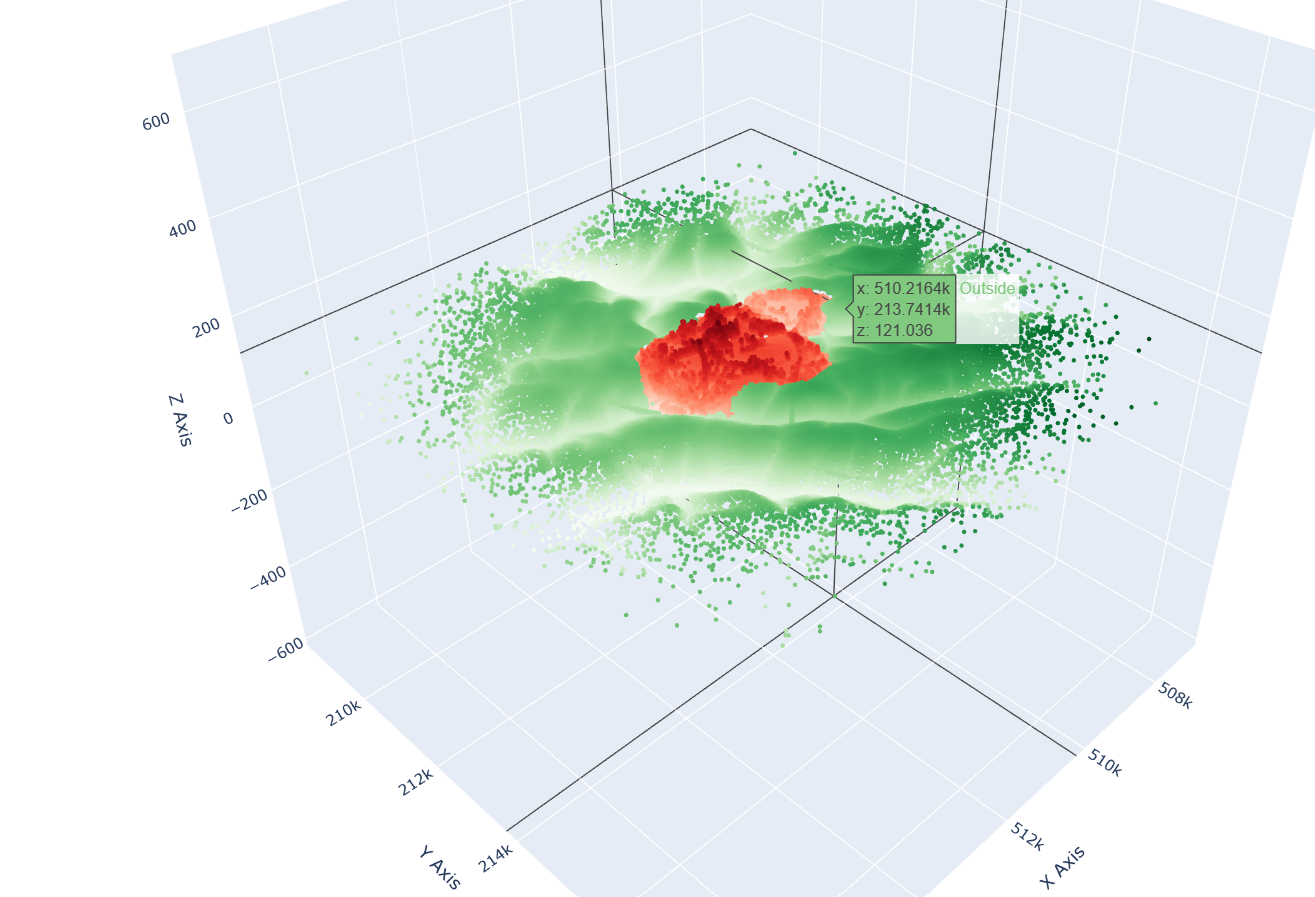
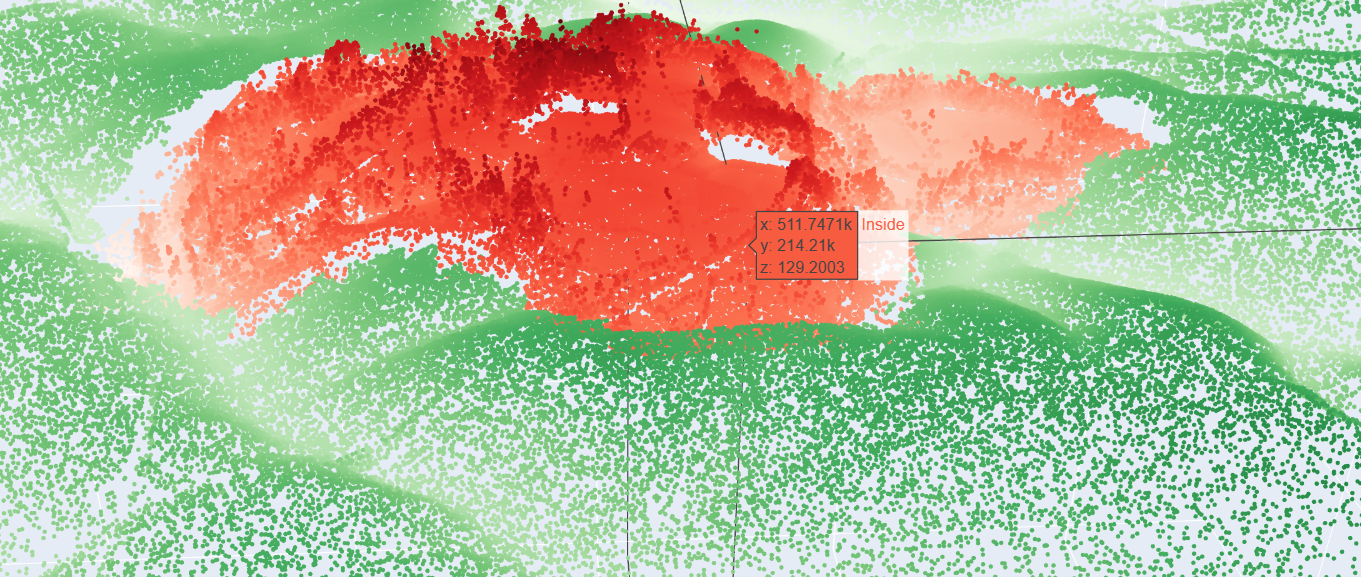
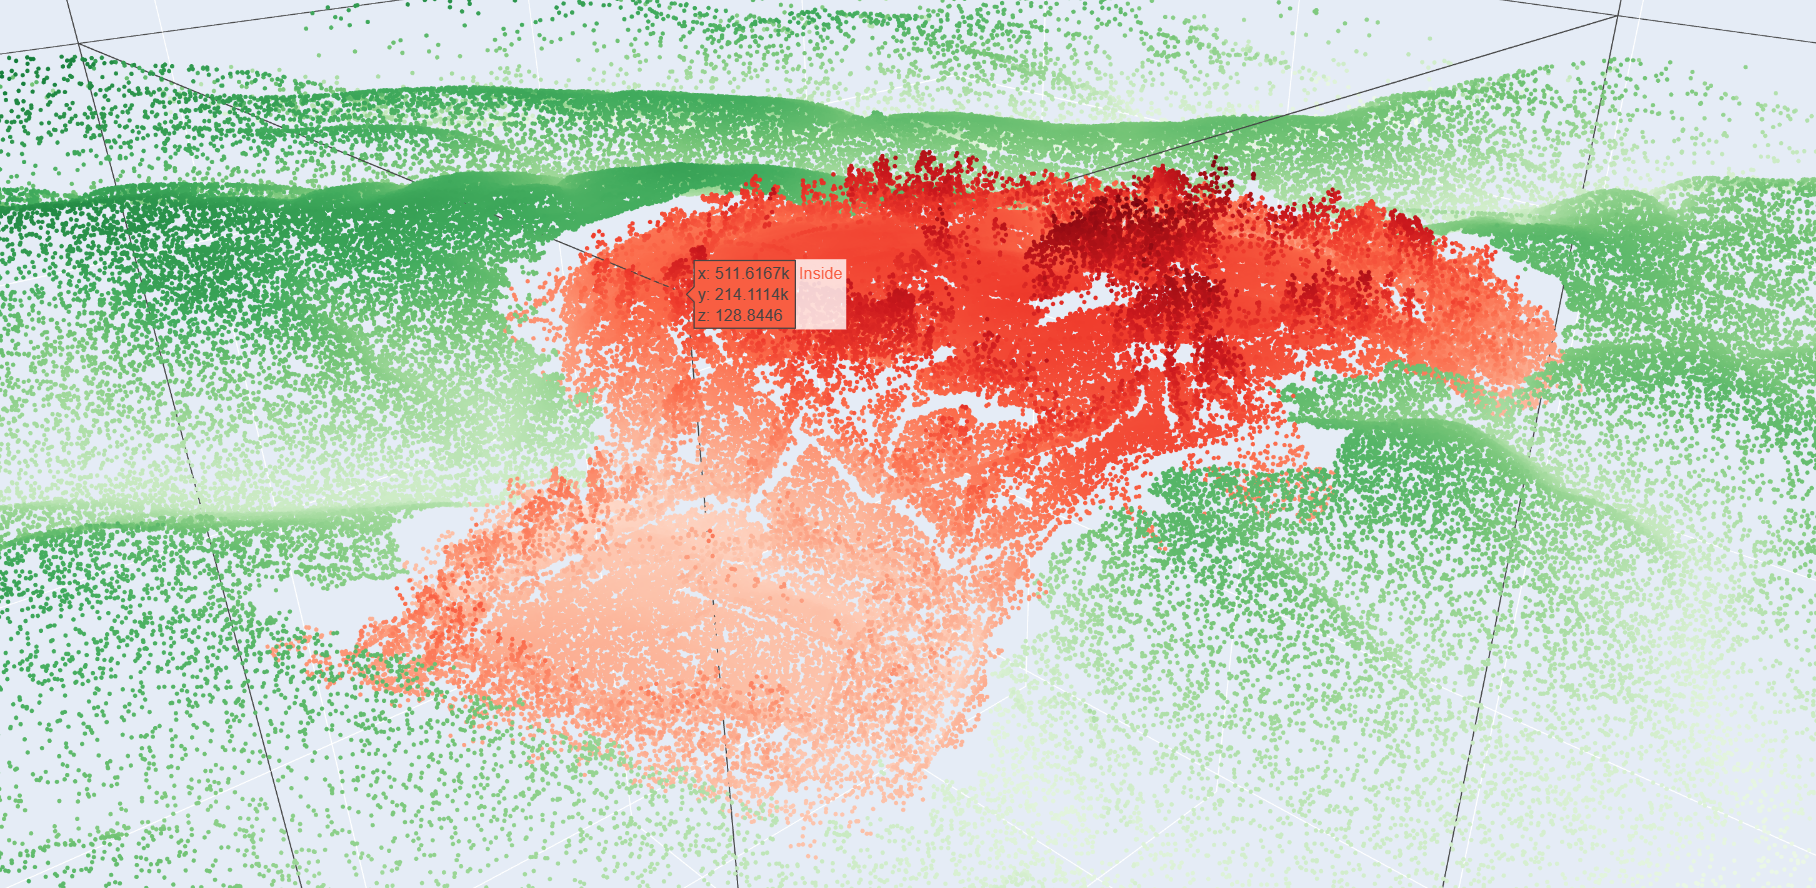
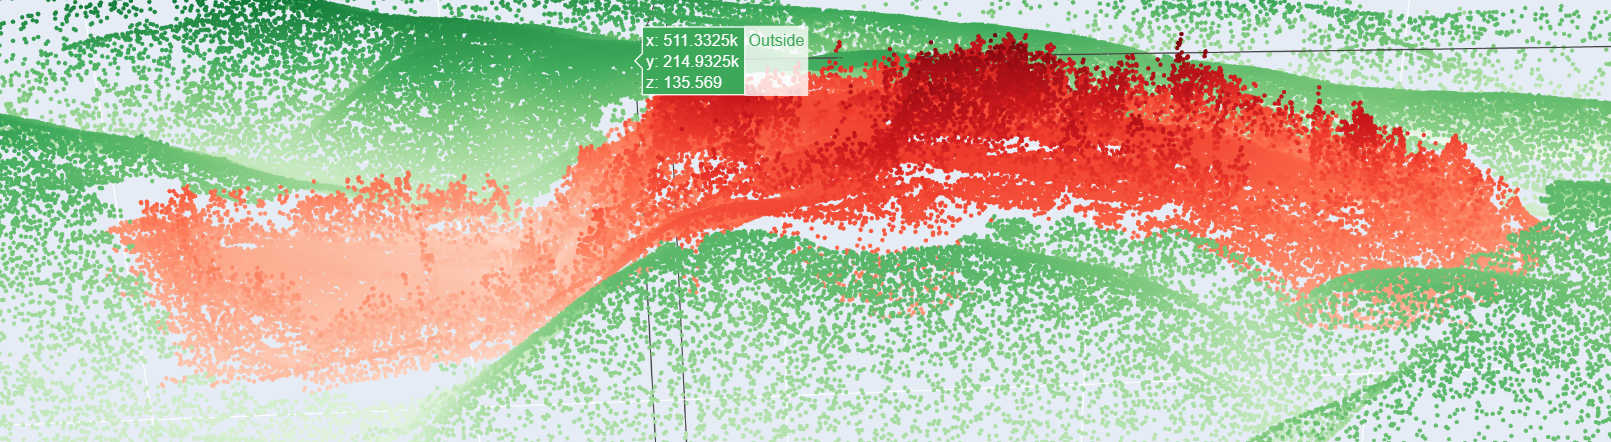

### A significant discrepancy exist between the height of the agricultural map and the one from the FIGSHARE

# Save the downsampled and the large ring file as a whole, into a new .obj file

In [17]:
adjusted_coords2 = np.zeros((adjusted_coords.shape[0], 6))
adjusted_coords2[:,:3] = adjusted_coords
adjusted_coords2[:,5] = 3
verts = np.vstack([final_mapping, adjusted_coords2])
stitch_rothamsted.create_obj_from_vertices(verts, 'Flight_Full.obj', 'Flight_Full.obj.mtl', ["material_0", "material_1", "Solid"], color=(1,1,1))

# adjusted_coords2 = np.zeros((adjusted_coords.shape[0], 6))
# adjusted_coords2[:,:3] = adjusted_coords
# adjusted_coords2[:,5] = 2
# verts = np.vstack([final_mapping, adjusted_coords2])
# stitch_rothamsted.create_obj_from_vertices(verts, 'Flight_2.obj', 'Flight_2.obj.mtl', ["material_0", "Solid"], color=(1,1,1))

NameError: name 'np' is not defined

## The ring is visible in blended green. 70 ms to generate a single image, versus 25 for the small BoB maps
## The model has 2 175 128 vertices

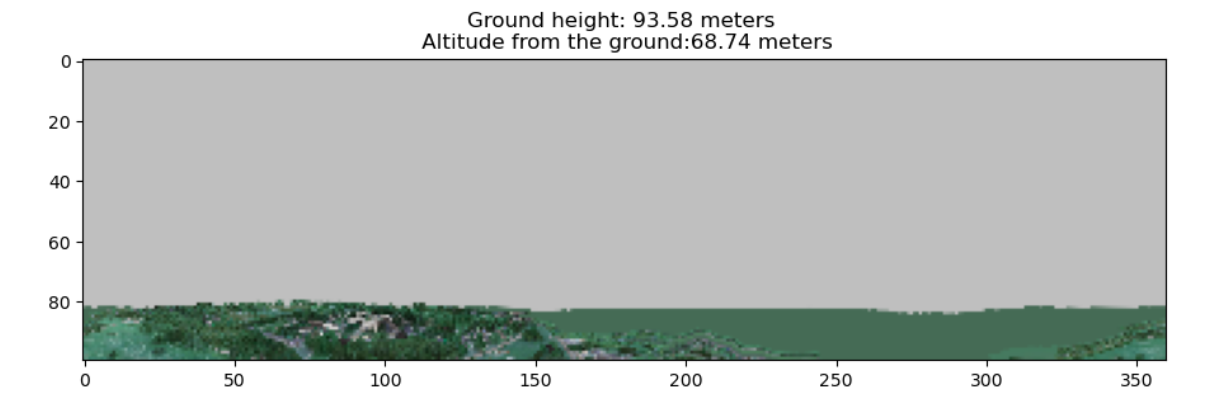
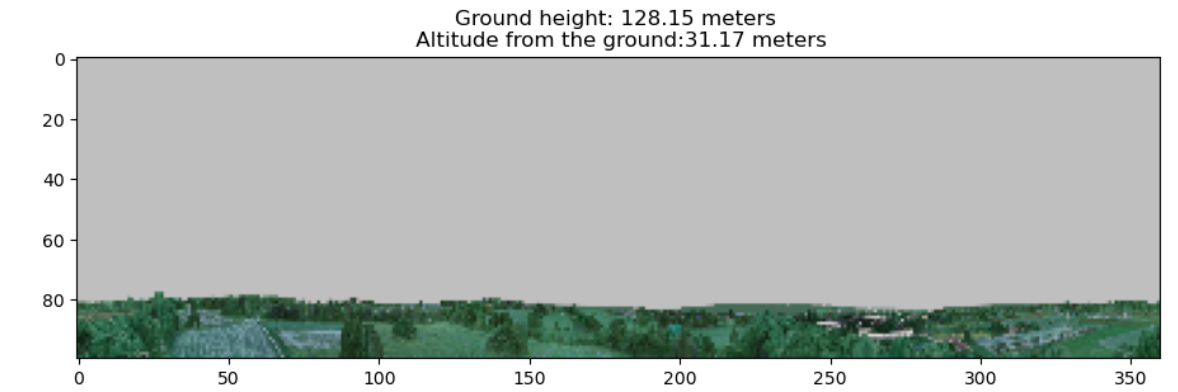
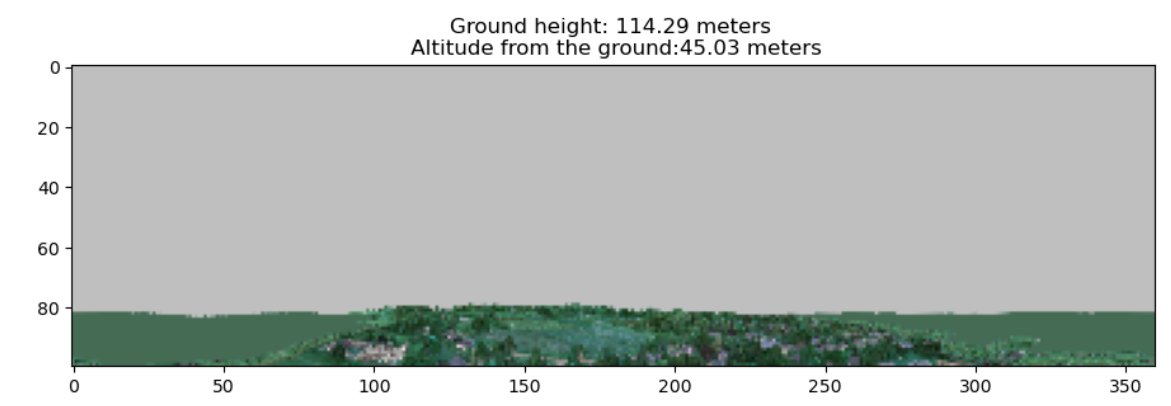

## FULL
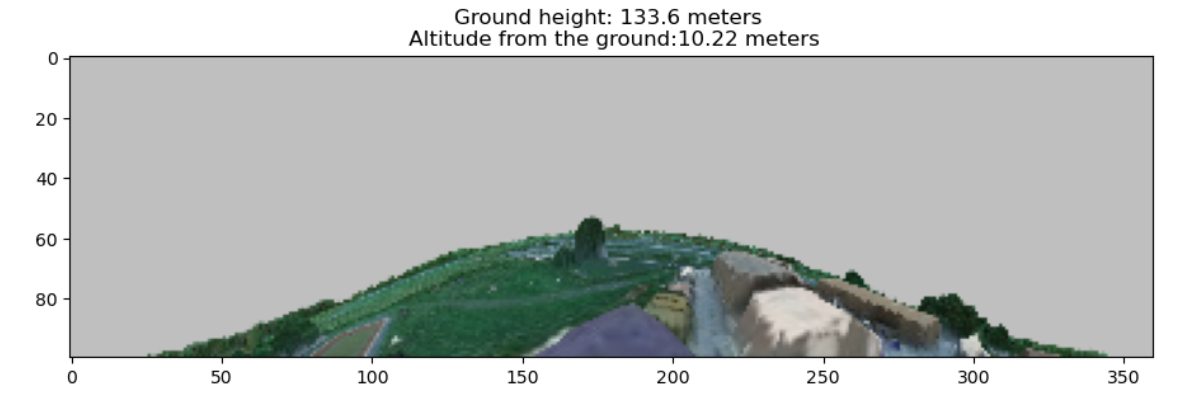

## BoB SMALL
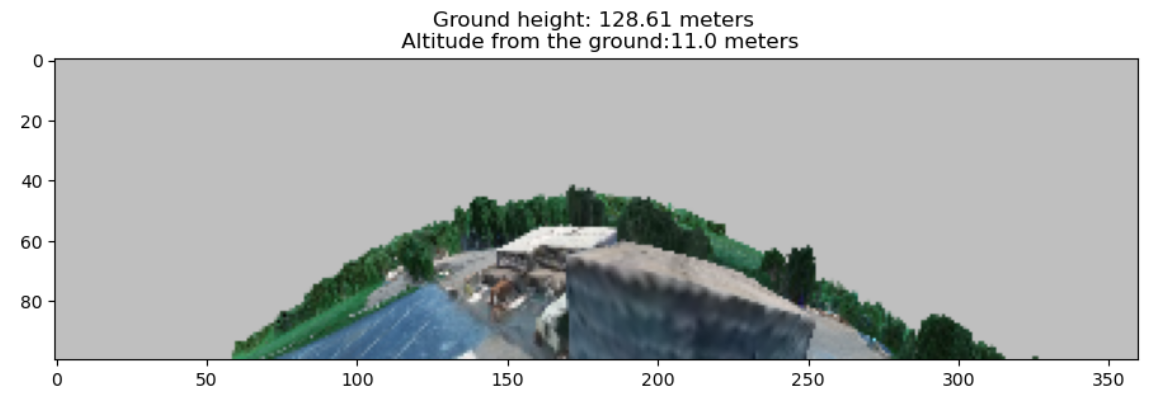

### Its not obvious here, but the small Bob maps are more detailed, the edges are sharper... etc
### Although being composed of 4 times more vertices, the full model is not so much slower to simulate, thus:
### perhaps next FULL map could be denser/better downsampling process/higher resolution of the .jpg file